Linear Regression => MSE=2900.1936 RMSE=53.8534 R2=0.4526
Best alpha (Ridge): 39.0694
Best alpha (Lasso): 1.4563
               Model          MSE       RMSE        R2
0  Linear Regression  2900.193628  53.853446  0.452603
1   Ridge Regression  2858.601520  53.465891  0.460453
2   Lasso Regression  2803.433565  52.947460  0.470866


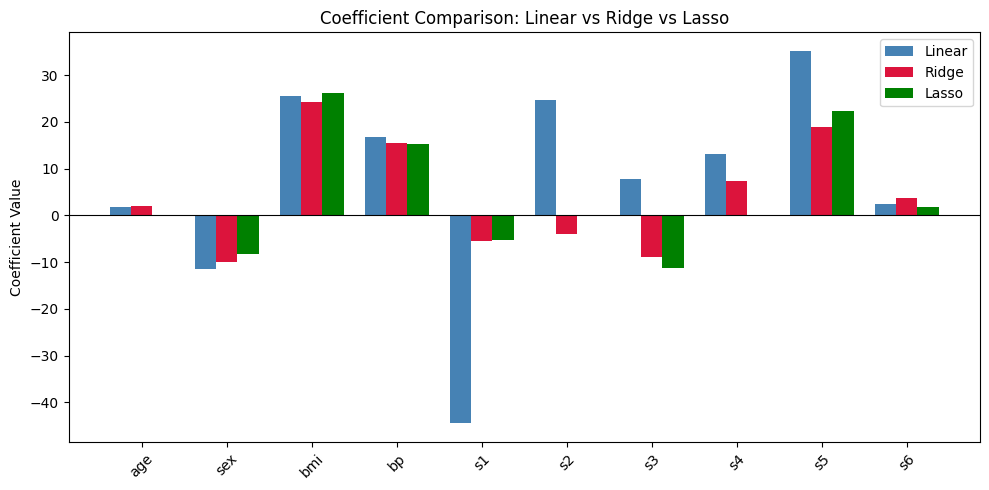

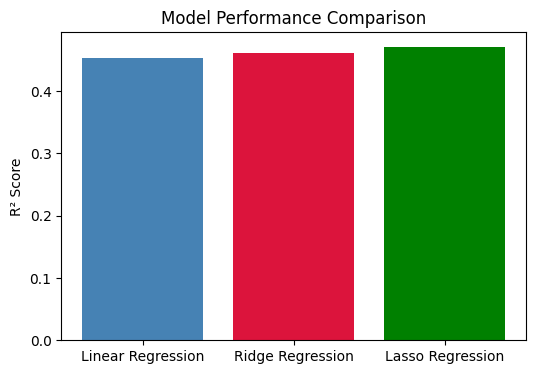

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = load_diabetes(as_frame=True)
df = data.frame

# Features and target
X = df.drop('target', axis=1).values
y = df['target'].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Linear Regression
lin_model = LinearRegression()
lin_model.fit(X_train_sc, y_train)
y_pred_lin = lin_model.predict(X_test_sc)

mse_lin = mean_squared_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)

print(f'Linear Regression => MSE={mse_lin:.4f} RMSE={mse_lin**0.5:.4f} R2={r2_lin:.4f}')

# Alpha values
alphas = np.logspace(-3, 2, 50)

# Ridge Regression
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_sc, y_train)
print(f'Best alpha (Ridge): {ridge_cv.alpha_:.4f}')

ridge_model = Ridge(alpha=ridge_cv.alpha_)
ridge_model.fit(X_train_sc, y_train)

# Lasso Regression
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
lasso_cv.fit(X_train_sc, y_train)
print(f'Best alpha (Lasso): {lasso_cv.alpha_:.4f}')

lasso_model = Lasso(alpha=lasso_cv.alpha_, max_iter=10000)
lasso_model.fit(X_train_sc, y_train)

# Compare performance
models = {
    'Linear Regression': lin_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_sc)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append((name, mse, mse**0.5, r2))

results_df = pd.DataFrame(
    results, columns=['Model', 'MSE', 'RMSE', 'R2']
)
print(results_df)

# Graph 1: Comparison of Regression Coefficients
feature_names = df.drop(columns=['target']).columns
x_pos = np.arange(len(feature_names))
width = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x_pos - width, lin_model.coef_, width, label='Linear', color='steelblue')
plt.bar(x_pos, ridge_model.coef_, width, label='Ridge', color='crimson')
plt.bar(x_pos + width, lasso_model.coef_, width, label='Lasso', color='green')

plt.xticks(x_pos, feature_names, rotation=45)
plt.ylabel('Coefficient Value')
plt.title('Coefficient Comparison: Linear vs Ridge vs Lasso')
plt.legend()
plt.axhline(0, color='black', lw=0.8)
plt.tight_layout()
plt.show()

# Graph 2: Comparison of Model Performance Using R-Squared Score
plt.figure(figsize=(6, 4))
plt.bar(
    results_df['Model'],
    results_df['R2'],
    color=['steelblue', 'crimson', 'green']
)
plt.ylabel('R² Score')
plt.title('Model Performance Comparison')
plt.show()
